# TASK-017 — Diversity & Bias Analysis

Compare the final synthetic AG News set with the [real AG News training data](https://huggingface.co/datasets/fancyzhx/ag_news). Measure lexical and embedding diversity, class drift, repeated wording, topic differences, and concrete problem examples.

In [1]:
from collections import Counter
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

ROOT = Path.cwd() if (Path.cwd() / "data" / "synthetic" / "final_8000.csv").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.filter_data import CATEGORIES, _embed, _real_screening_pool, normalize, words

DATA = ROOT / "data" / "synthetic"
raw = pd.read_csv(DATA / "full_unfiltered.csv")
filtered = pd.read_csv(DATA / "full_filtered.csv")
final = pd.read_csv(DATA / "final_8000.csv")
with requests.Session() as session:
    real_pool = _real_screening_pool(session)
real_pool["category"] = real_pool.label.map(CATEGORIES)
categories = list(CATEGORIES.values())

assert len(raw) == 8_000 and len(final) == 8_000
assert len(real_pool) == 800 and real_pool.text.notna().all()
assert final.sample_id.is_unique and final.text.map(normalize).is_unique
assert final.category.value_counts().to_dict() == {name: 2_000 for name in categories}

# Equal class counts and article counts make corpus-level diversity comparable.
real = (real_pool.groupby("label", group_keys=False).sample(n=100, random_state=17)
        .sort_values(["label", "row_idx"]).reset_index(drop=True))
synthetic = (final.groupby("label", group_keys=False).sample(n=100, random_state=17)
             .sort_values(["label", "sample_id"]).reset_index(drop=True))
matched = {"AG News": real, "Synthetic": synthetic}
assert all(frame.category.value_counts().eq(100).all() for frame in matched.values())
display(pd.DataFrame({name: frame.category.value_counts().reindex(categories)
                      for name, frame in matched.items()}))

,AG News,Synthetic
category,,
World,100,100
Sports,100,100
Business,100,100
Sci/Tech,100,100


In [2]:
sources = {"AG News matched": real, "Unfiltered": raw,
           "Filtered": filtered, "Final": final}
shares = pd.DataFrame({name: frame.category.value_counts(normalize=True).reindex(categories)
                       for name, frame in sources.items()})
drift = pd.DataFrame({
    "source": shares.columns,
    "rows": [len(frame) for frame in sources.values()],
    "total_variation_from_25pct": [0.5 * (shares[name] - 0.25).abs().sum()
                                   for name in shares.columns],
    "max_class_deviation_pp": [100 * (shares[name] - 0.25).abs().max()
                               for name in shares.columns],
})
display((100 * shares).round(2).rename_axis("category"))
display(drift.round(4))

,AG News matched,Unfiltered,Filtered,Final
category,,,,
World,25.0,25.0,24.56,25.0
Sports,25.0,25.0,24.60,25.0
Business,25.0,25.0,25.45,25.0
Sci/Tech,25.0,25.0,25.39,25.0


,source,rows,total_variation_from_25pct,max_class_deviation_pp
0,AG News matched,400,0.0000,0.0000
1,Unfiltered,8000,0.0000,0.0000
2,Filtered,7427,0.0084,0.4477
3,Final,8000,0.0000,0.0000


In [3]:
def distinct_n_first35(texts, n):
    grams = [tuple(tokens[i:i+n])
             for text in texts
             for tokens in [words(text)[:35]]
             for i in range(len(tokens) - n + 1)]
    return len(set(grams)) / len(grams) if grams else np.nan

lexical_rows = []
for name, frame in matched.items():
    for category in categories:
        group = frame[frame.category.eq(category)]
        lengths = group.text.map(lambda text: len(words(text)))
        lexical_rows.append({
            "source": name, "category": category, "articles": len(group),
            "mean_words_full": float(lengths.mean()),
            "distinct_1_first35": distinct_n_first35(group.text, 1),
            "distinct_2_first35": distinct_n_first35(group.text, 2),
        })
lexical = pd.DataFrame(lexical_rows)
display(lexical.round(3))

,source,category,articles,mean_words_full,distinct_1_first35,distinct_2_first35
0,AG News,World,100,38.55,0.403,0.857
1,AG News,Sports,100,36.90,0.403,0.856
2,AG News,Business,100,38.43,0.421,0.882
3,AG News,Sci/Tech,100,37.41,0.426,0.889
4,Synthetic,World,100,66.55,0.294,0.758
5,Synthetic,Sports,100,68.03,0.302,0.729
6,Synthetic,Business,100,66.66,0.292,0.755
7,Synthetic,Sci/Tech,100,69.52,0.272,0.719


In [4]:
combined = pd.concat([real.assign(source="AG News"),
                      synthetic.assign(source="Synthetic")], ignore_index=True)
with requests.Session() as session:
    vectors = _embed(session, combined.text.tolist())

semantic_rows = []
for source in matched:
    for category in categories:
        positions = combined.index[(combined.source.eq(source) & combined.category.eq(category))].to_numpy()
        similarity = vectors[positions] @ vectors[positions].T
        pairs = similarity[np.triu_indices(len(positions), k=1)]
        semantic_rows.append({
            "source": source, "category": category, "pairs": len(pairs),
            "mean_pairwise_cosine": float(pairs.mean()),
            "semantic_diversity": float(1 - pairs.mean()),
            "pairs_cosine_ge_0_90": int((pairs >= 0.90).sum()),
        })
semantic = pd.DataFrame(semantic_rows)
display(semantic.round(3))

,source,category,pairs,mean_pairwise_cosine,semantic_diversity,pairs_cosine_ge_0_90
0,AG News,World,4950,0.088,0.912,2
1,AG News,Sports,4950,0.128,0.872,2
2,AG News,Business,4950,0.100,0.900,1
3,AG News,Sci/Tech,4950,0.103,0.897,0
4,Synthetic,World,4950,0.193,0.807,0
5,Synthetic,Sports,4950,0.228,0.772,0
6,Synthetic,Business,4950,0.226,0.774,0
7,Synthetic,Sci/Tech,4950,0.228,0.772,0


Diversity is measured on 100 real and 100 synthetic articles per class. Only the first 35 words enter lexical and topic comparisons; embeddings use full text. The AG News sample is drawn from fixed training-set offsets and is illustrative, not a population estimate.

In [5]:
# Unique full texts can still reuse the same headline or opening.
headline_key = final.headline.map(normalize)
headline_counts = headline_key.value_counts()
repeated = final.assign(headline_key=headline_key,
                        repeat_n=headline_key.map(headline_counts))
headline_repetition = (repeated.assign(repeated=repeated.repeat_n.gt(1))
                       .groupby("category").repeated.agg(["sum", "mean"])
                       .reindex(categories))
headline_repetition.columns = ["articles_with_repeated_headline", "share_with_repeated_headline"]
display(headline_repetition.round(3))
print("Repeated-headline articles:", int(repeated.repeat_n.gt(1).sum()),
      "across", int(headline_counts.gt(1).sum()), "distinct repeated headlines")

openings = (final.assign(opening=final.headline.map(lambda text: " ".join(words(text)[:3])))
            .groupby(["category", "opening"]).size().rename("count").reset_index())
display(openings.sort_values(["category", "count"], ascending=[True, False])
        .groupby("category").head(5).reset_index(drop=True))

,articles_with_repeated_headline,share_with_repeated_headline
category,,
World,21,0.010
Sports,62,0.031
Business,27,0.014
Sci/Tech,98,0.049


Repeated-headline articles: 208 across 68 distinct repeated headlines


,category,opening,count
0,Business,novacore announces expansion,19
1,Business,novagrid announces expansion,19
2,Business,southern new zealand,16
3,Business,são paulo based,14
4,Business,novatech announces expansion,12
5,Sci/Tech,quantum ai team,96
6,Sci/Tech,quantum ai startup,25
7,Sci/Tech,southern new zealand,23
8,Sci/Tech,quantum sensors detect,17
9,Sci/Tech,indonesia s east,14


In [6]:
# Compare article prevalence of terms after matching lengths and excluding source tags.
stop_words = set(ENGLISH_STOP_WORDS) | {"reuters", "afp", "ap", "quot", "com"}
topic_rows = []
for category in categories:
    pair = pd.concat([real[real.category.eq(category)].assign(source="AG News"),
                      synthetic[synthetic.category.eq(category)].assign(source="Synthetic")],
                     ignore_index=True)
    snippets = pair.text.map(lambda text: " ".join(words(text)[:35]))
    vectorizer = CountVectorizer(stop_words=list(stop_words), binary=True,
                                 ngram_range=(1, 2), min_df=5,
                                 token_pattern=r"(?u)\b[a-z][a-z]+\b")
    matrix = vectorizer.fit_transform(snippets)
    terms = vectorizer.get_feature_names_out()
    real_rate = np.asarray(matrix[:100].sum(axis=0)).ravel() / 100
    synth_rate = np.asarray(matrix[100:].sum(axis=0)).ravel() / 100
    for term, r, s in zip(terms, real_rate, synth_rate):
        if (r + s) >= 0.08:
            topic_rows.append({"category": category, "term": term,
                               "real_pct": 100 * r, "synthetic_pct": 100 * s,
                               "gap_pp": 100 * (s - r)})
topics = pd.DataFrame(topic_rows)
distinctive = pd.concat([
    topics[topics.category.eq(category)].nlargest(5, "gap_pp").assign(overrepresented_in="Synthetic")
    for category in categories
] + [
    topics[topics.category.eq(category)].nsmallest(5, "gap_pp").assign(overrepresented_in="AG News")
    for category in categories
], ignore_index=True)
display(distinctive.round(1))

,category,term,real_pct,synthetic_pct,gap_pp,overrepresented_in
0,World,new,10.0,32.0,22.0,Synthetic
1,World,launched,1.0,22.0,21.0,Synthetic
2,World,regional,1.0,22.0,21.0,Synthetic
3,World,council,2.0,22.0,20.0,Synthetic
4,World,amid,1.0,18.0,17.0,Synthetic
5,Sports,match,5.0,32.0,27.0,Synthetic
6,Sports,amid,1.0,26.0,25.0,Synthetic
7,Sports,local,0.0,24.0,24.0,Synthetic
8,Sports,final,5.0,25.0,20.0,Synthetic
9,Sports,regional,0.0,16.0,16.0,Synthetic


In [7]:
# Five concrete final-dataset examples; all have unique article text but duplicate headlines.
problem_rows = []
for category, n in [("Sports", 2), ("Business", 1), ("Sci/Tech", 2)]:
    selected = (repeated[(repeated.category.eq(category)) & (repeated.repeat_n.gt(1))]
                .sort_values(["repeat_n", "sample_id"], ascending=[False, True])
                .drop_duplicates("headline_key").head(n))
    for row in selected.itertuples():
        peers = repeated.loc[(repeated.headline_key.eq(row.headline_key)) &
                             (repeated.sample_id.ne(row.sample_id)), "sample_id"]
        problem_rows.append({"sample_id": row.sample_id, "category": category,
                             "headline": row.headline, "summary": row.summary,
                             "repeated_headline_count": row.repeat_n,
                             "another_sample_id": peers.iloc[0],
                             "problem": "Exact headline reused by distinct articles"})
problems = pd.DataFrame(problem_rows)
assert len(problems) == 5 and problems.sample_id.is_unique
display(problems)

,sample_id,category,headline,summary,repeated_headline_count,another_sample_id,problem
0,1_0050,Sports,Alpine Ski Team Triumphs in Winter Cup Final,The Swiss Alpine Ski Team secured a historic w...,9,1_0730,Exact headline reused by distinct articles
1,1_0130,Sports,Falcons Edge Raiders in Thrilling Week 12 Clash,The Atlanta Falcons secured a 24-21 victory ov...,4,1_0260,Exact headline reused by distinct articles
2,2_0080,Business,NovaTech Announces Expansion of AI-Powered Sup...,"NovaTech, a Silicon Valley-based logistics fir...",8,2_1050,Exact headline reused by distinct articles
3,3_0030,Sci/Tech,Quantum AI Team Unveils Real-Time Neural Proce...,The Zurich-based quantum startup QubitEdge has...,9,3_0270,Exact headline reused by distinct articles
4,3_0100,Sci/Tech,Quantum AI Team Unveils First Real-Time Neural...,Researchers at NovaCore Labs have introduced Q...,6,3_1620,Exact headline reused by distinct articles


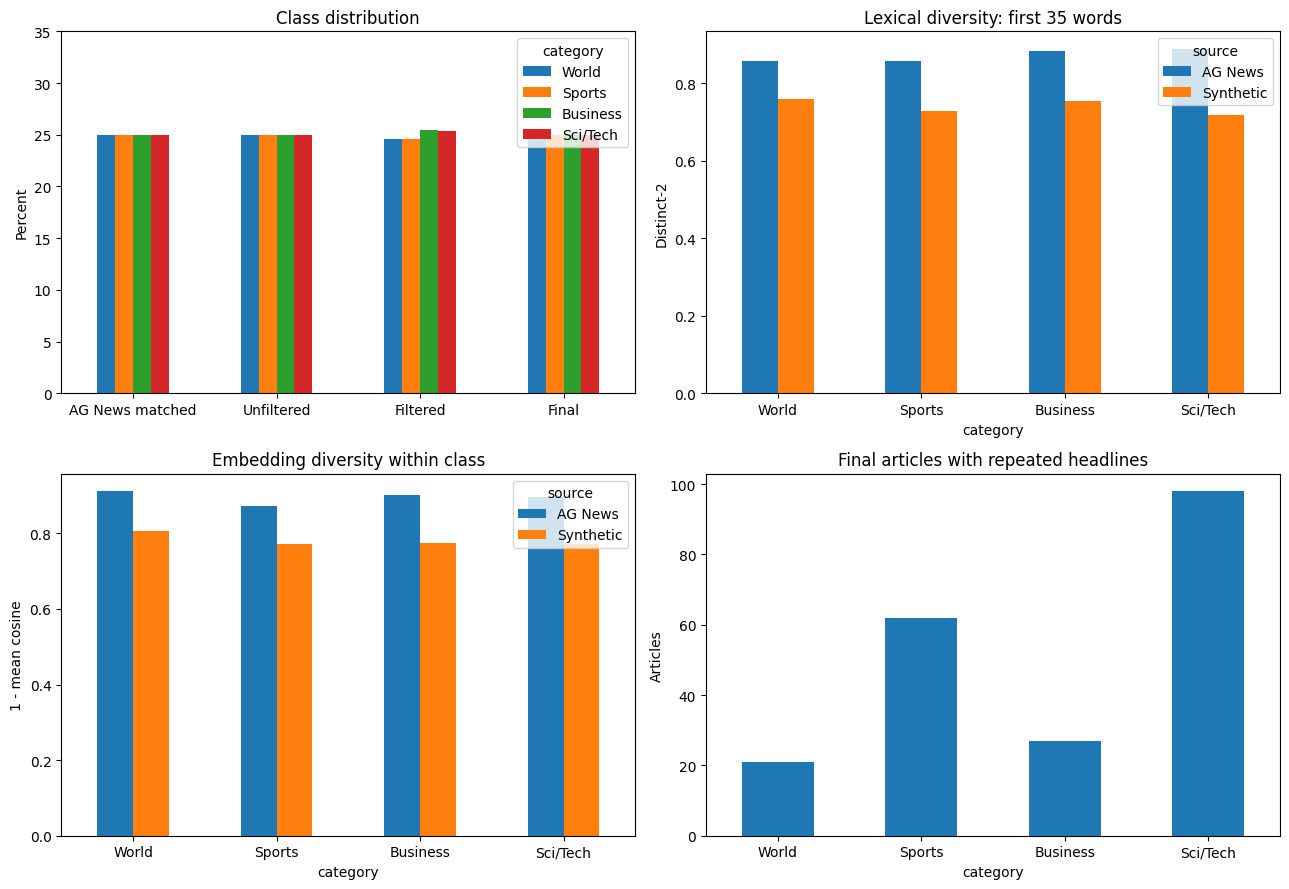

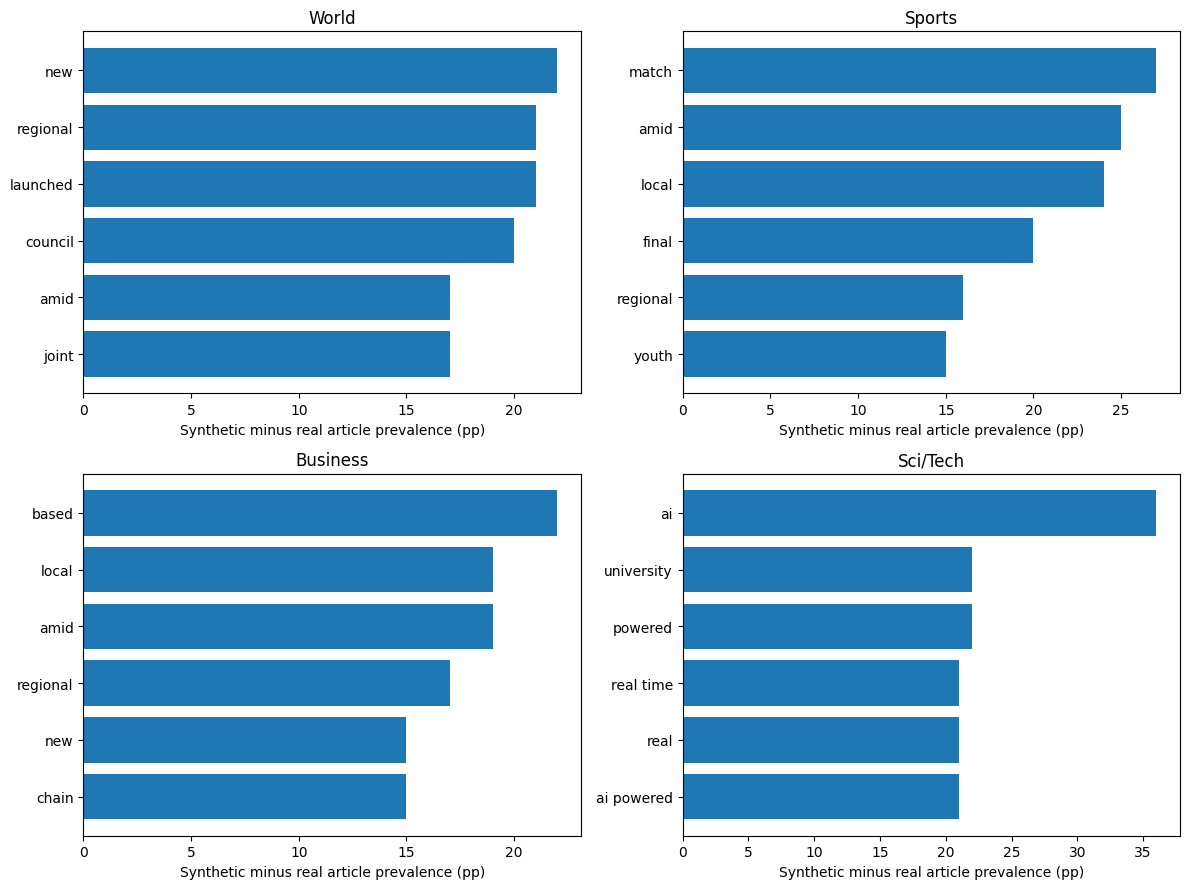

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
(100 * shares).T.plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title="Class distribution", ylabel="Percent", ylim=(0, 35))
lexical.pivot(index="category", columns="source", values="distinct_2_first35").reindex(categories).plot.bar(ax=axes[0, 1], rot=0)
axes[0, 1].set(title="Lexical diversity: first 35 words", ylabel="Distinct-2")
semantic.pivot(index="category", columns="source", values="semantic_diversity").reindex(categories).plot.bar(ax=axes[1, 0], rot=0)
axes[1, 0].set(title="Embedding diversity within class", ylabel="1 - mean cosine")
headline_repetition.articles_with_repeated_headline.plot.bar(ax=axes[1, 1], rot=0)
axes[1, 1].set(title="Final articles with repeated headlines", ylabel="Articles")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, category in zip(axes.flat, categories):
    top = topics[topics.category.eq(category)].nlargest(6, "gap_pp").sort_values("gap_pp")
    ax.barh(top.term, top.gap_pp)
    ax.set(title=category, xlabel="Synthetic minus real article prevalence (pp)")
fig.tight_layout()
plt.show()

In [9]:
lex_means = lexical.groupby("source").distinct_2_first35.mean()
sem_means = semantic.groupby("source").semantic_diversity.mean()
print("Mean class-level distinct-2, real/synthetic:",
      round(lex_means["AG News"], 3), round(lex_means["Synthetic"], 3))
print("Mean class-level embedding diversity, real/synthetic:",
      round(sem_means["AG News"], 3), round(sem_means["Synthetic"], 3))
print("Final total-variation drift from equal classes:",
      round(float(drift.set_index("source").at["Final", "total_variation_from_25pct"]), 4))
print("Filtered total-variation drift from equal classes:",
      round(float(drift.set_index("source").at["Filtered", "total_variation_from_25pct"]), 4))
print("Repeated headlines in final set:", int(repeated.repeat_n.gt(1).sum()), "of", len(final))
print("Five documented problem examples:", ", ".join(problems.sample_id))
print("Term gaps indicate sample-specific topic and vocabulary differences, not demographic bias.")

Mean class-level distinct-2, real/synthetic: 0.871 0.74
Mean class-level embedding diversity, real/synthetic: 0.896 0.781
Final total-variation drift from equal classes: 0.0
Filtered total-variation drift from equal classes: 0.0084
Repeated headlines in final set: 208 of 8000
Five documented problem examples: 1_0050, 1_0130, 2_0080, 3_0030, 3_0100
Term gaps indicate sample-specific topic and vocabulary differences, not demographic bias.


The five examples document headline repetition, not factual errors. Topic differences can reflect the source corpora's dates, selection, and synthetic prompt scenarios; they do not establish demographic bias.